# 04 · Tools & the ReAct Agent  🟡 Intermediate

An **agent** = an LLM in a loop that can **call tools** and decides by itself when it is done:

```
        ┌──────────────┐  tool_calls?  ┌───────┐
START → │  agent (LLM) │ ────yes─────▶ │ tools │
        └──────────────┘ ◀──────────── └───────┘
               │ no
               ▼
              END
```
We build it **from scratch first**, then with LangGraph's prebuilt pieces, then with a one-liner.

In [1]:
from helpers import get_llm, show_graph, print_messages

llm = get_llm()   # ChatAnthropic -> Claude, key read from CLAUDE_KEY in .env

## 1. Define tools

The `@tool` decorator turns a function into a tool. The **docstring and type hints become the schema** Claude sees, so write them well.

In [2]:
from langchain_core.tools import tool

@tool
def get_weather(city: str) -> str:
    """Get the current weather for a city."""
    fake_db = {"paris": "18°C, cloudy", "tokyo": "24°C, sunny", "mumbai": "31°C, humid"}
    return fake_db.get(city.lower(), "20°C, clear")

@tool
def multiply(a: float, b: float) -> float:
    """Multiply two numbers."""
    return a * b

@tool
def divide(a: float, b: float) -> float:
    """Divide a by b."""
    return a / b

tools = [get_weather, multiply, divide]

In [3]:
print(get_weather.name, "|", get_weather.description)
print(get_weather.args)

get_weather | Get the current weather for a city.
{'city': {'title': 'City', 'type': 'string'}}


## 2. Let Claude *request* a tool call

`bind_tools` tells the model which tools exist. The model doesn't run them, it returns `tool_calls`.

In [4]:
llm_with_tools = llm.bind_tools(tools)
msg = llm_with_tools.invoke("What's the weather in Paris?")
print("text:", repr(msg.text))
print("tool_calls:", msg.tool_calls)

text: ''
tool_calls: [{'name': 'get_weather', 'args': {'city': 'Paris'}, 'id': 'toolu_017MEtnFcfDHZ9sTndAnm5Kk', 'type': 'tool_call'}]


In [5]:
# Running a tool with a tool_call returns a ToolMessage (linked by tool_call_id)
tool_msg = get_weather.invoke(msg.tool_calls[0])
tool_msg

ToolMessage(content='18°C, cloudy', name='get_weather', tool_call_id='toolu_017MEtnFcfDHZ9sTndAnm5Kk')

## 3. ReAct agent from scratch

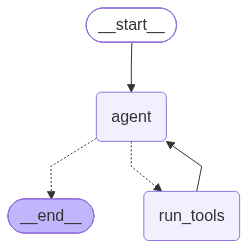

In [6]:
from typing import Literal
from langchain_core.messages import SystemMessage
from langgraph.graph import StateGraph, MessagesState, START, END

SYSTEM = SystemMessage("You are a helpful assistant. Use tools when they help. Be concise.")
tools_by_name = {t.name: t for t in tools}

def agent(state: MessagesState):
    return {"messages": [llm_with_tools.invoke([SYSTEM] + state["messages"])]}

def run_tools(state: MessagesState):
    last = state["messages"][-1]
    results = [tools_by_name[call["name"]].invoke(call) for call in last.tool_calls]
    return {"messages": results}

def should_continue(state: MessagesState) -> Literal["run_tools", "__end__"]:
    return "run_tools" if state["messages"][-1].tool_calls else END

b = StateGraph(MessagesState)
b.add_node(agent); b.add_node(run_tools)
b.add_edge(START, "agent")
b.add_conditional_edges("agent", should_continue)
b.add_edge("run_tools", "agent")               # 🔁 the loop that makes it an agent
scratch_agent = b.compile()
show_graph(scratch_agent)

In [7]:
result = scratch_agent.invoke({"messages": [("user",
    "What's the weather in Paris and Tokyo? Then multiply the two temperatures (just the numbers).")]})
print_messages(result["messages"])

===== HUMAN =====
What's the weather in Paris and Tokyo? Then multiply the two temperatures (just the numbers).
===== AI =====
  -> calls tool get_weather({'city': 'Paris'})
  -> calls tool get_weather({'city': 'Tokyo'})
===== TOOL [get_weather] =====
18°C, cloudy
===== TOOL [get_weather] =====
24°C, sunny
===== AI =====
  -> calls tool multiply({'a': 18, 'b': 24})
===== TOOL [multiply] =====
432.0
===== AI =====
It's 18°C and cloudy in Paris, and 24°C and sunny in Tokyo. Multiplying the two temperatures gives 18 × 24 = **432**.


Notice: Claude asked for **both** weather lookups in parallel, then used the results to call `multiply`.

## 4. Same agent with prebuilt `ToolNode` + `tools_condition`

`ToolNode` runs tool calls (in parallel) and `tools_condition` is the router above.
`handle_tool_errors=True` turns exceptions into an error `ToolMessage` so the model can recover instead of crashing.

In [8]:
from langgraph.prebuilt import ToolNode, tools_condition

b = StateGraph(MessagesState)
b.add_node("agent", agent)
b.add_node("tools", ToolNode(tools, handle_tool_errors=True))
b.add_edge(START, "agent")
b.add_conditional_edges("agent", tools_condition)   # -> "tools" or END
b.add_edge("tools", "agent")
react_agent = b.compile()

result = react_agent.invoke({"messages": [("user", "Use the divide tool to compute 10 / 0, then tell me what happened.")]})
print_messages(result["messages"])

===== HUMAN =====
Use the divide tool to compute 10 / 0, then tell me what happened.
===== AI =====
  -> calls tool divide({'a': 10, 'b': 0})
===== TOOL [divide] =====
Error: ZeroDivisionError('float division by zero')
 Please fix your mistakes.
===== AI =====
I called `divide(10, 0)` and the tool returned an error: **`ZeroDivisionError('float division by zero')`**. It didn't give back a number.

That's the right outcome. Dividing by zero has no answer in standard math, because no number times 0 equals 10. As the divisor shrinks toward zero from the positive side, 10 / *b* grows without limit (+∞). From the negative side, it drops without limit (−∞). Since the two sides don't agree, 10 / 0 is undefined. The tool raised an error rather than returning a misleading value like infinity.

The error message also said "Please fix your mistakes," but nothing about the call can be changed to make it work. The problem is the math itself, so I didn't retry.


## 5. One-liner: `create_agent`

For the standard pattern, LangChain's `create_agent` builds this exact graph (on top of LangGraph) for you.

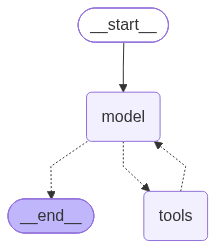

Mumbai is warmer right now, by **13°C**.

- **Mumbai:** 31°C and humid
- **Paris:** 18°C and cloudy


In [9]:
from langchain.agents import create_agent

quick_agent = create_agent(llm, tools=tools, system_prompt="You are a concise travel assistant.")
show_graph(quick_agent)
result = quick_agent.invoke({"messages": [("user", "Is it warmer in Mumbai or Paris right now, and by how much?")]})
print(result["messages"][-1].text)

## ✅ Recap
* Tools = functions + schema; the model returns `tool_calls`, **your graph executes them**.
* Agent loop: `agent → tools → agent …` until no tool calls.
* Build it yourself to understand, use `ToolNode`/`tools_condition` or `create_agent` in practice.

**Try it:** add a `convert_currency(amount, from_currency, to_currency)` tool with fake rates and ask a multi-step question.